# Lab 1.6 · Mixture of experts

**15–20 minutes · CPU · Python standard library**

## How to work through this notebook

Read the worked example, run the setup, then complete the exercises in order. Replace each `return None` placeholder with your code and run the cell below to check your result. Use the wrap-up to explain the output in your own words.

## Concepts and worked example

A mixture-of-experts layer has multiple expert networks and a **router** that decides which ones to run for each token. The router produces one score per expert. In this lab, top-k routing keeps the k highest scores, normalizes them into weights with softmax, and combines the selected expert outputs. Trained models can use different scoring and normalization rules.

Suppose one token gives expert scores `[2, 0, 1]`. Top-1 uses expert 0 with weight 1. Top-2 uses experts 0 and 2 with weights of about `0.73` and `0.27`. If their outputs are 10 and 4, the combined output is about 8.4. Expert 1 is skipped in both runs.

The notebook supplies simple scalar expert functions and fixed router scores. Expert calls measure work in this example. If many tokens select the same expert, its call count can remain high even though most experts are skipped per token. In a distributed model, that imbalance can matter alongside communication and batching.

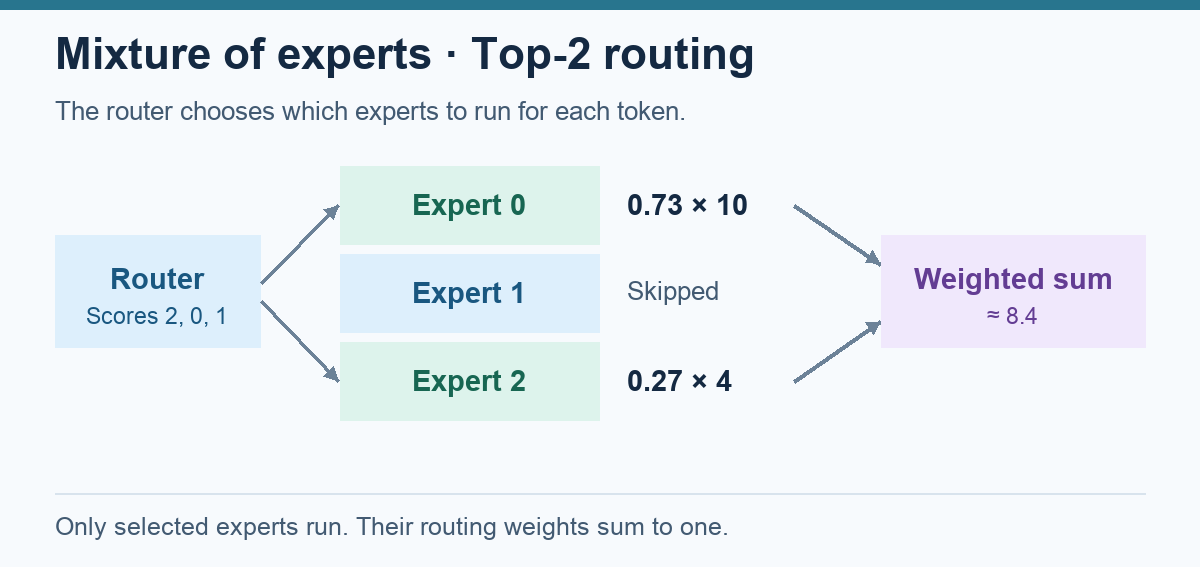

## Exercise map

1. **Select and weight experts** — Sort expert IDs by score, retain the best k, and normalize the selected scores with softmax.
2. **Combine outputs and count calls** — Route each token, run only its chosen experts, and accumulate the weighted output and per-expert counts.

[Open the lab guide](README.md) for the exercise checklist.

In [ ]:
from math import exp, isclose

tokens = [2, 4, 6, 8]
scores = [[4, 2, 1], [3, 1, 2], [4, 3, 1], [2, 3, 1]]
experts = [lambda x: 2 * x, lambda x: x + 1, lambda x: -x]

## Exercise 1. Select and weight experts

Return a list of (expert index, weight) pairs. Sort indices by descending score, keep the top k, and apply softmax to the selected scores. Break ties by keeping the lower index first. All examples have 1 ≤ k ≤ 3.

**Implementation hint** — Keep indices attached to their scores. Subtract the largest selected score before exponentiating.

**After running the check** — Check the selected IDs, their order, and that the weights sum to one. Top-1 should give the selected expert full weight.

In [ ]:
def route(scores, k):
    return None

In [ ]:
top_two = route(scores[0], 2)
if top_two is not None:
    assert [i for i, _ in top_two] == [0, 1]
    assert top_two[0][1] > top_two[1][1] and isclose(sum(w for _, w in top_two), 1)
    assert route([1, 1, 0], 1) == [(0, 1.0)]
    print("PASS — selected experts and weights:", top_two)

### Read the result

Track expert IDs alongside their scores. A top-1 result gives its single expert all the weight.

## Exercise 2. Combine outputs and count calls

For each token, use its routing scores to select experts. Only call the selected experts. Return the weighted output per token and a list of call counts indexed by expert. Predict which expert gets the most calls.

**Implementation hint** — Initialize counts once per batch. Increment the corresponding counter exactly where you call an expert.

**After running the check** — Compare total calls and the busiest expert for top-1 and top-2. Also compare both with evaluating every expert for every token.

In [ ]:
def mixture(tokens, scores, k):
    return None

In [ ]:
check_passed = False
if top_two is not None:
    first = mixture(tokens, scores, 1)
    second = mixture(tokens, scores, 2)
    if first is not None and second is not None:
        assert first == ([4.0, 8.0, 12.0, 9.0], [3, 1, 0])
        assert second[1] == [4, 3, 1]
        assert isclose(second[0][0], 4 * top_two[0][1] + 3 * top_two[1][1])
        print("Top-1 calls:", first[1], "Top-2 calls:", second[1])
        print("Evaluating every expert would use", len(tokens) * len(experts), "calls.")
        print("PASS — weighted outputs and expert loads")
        check_passed = True
if not check_passed:
    print("Complete route and mixture and rerun the checks in order.")

### Read the result

Count calls for each expert and compare the maximum as well as the sum. The busiest expert can dominate a distributed step.

## Compare your results

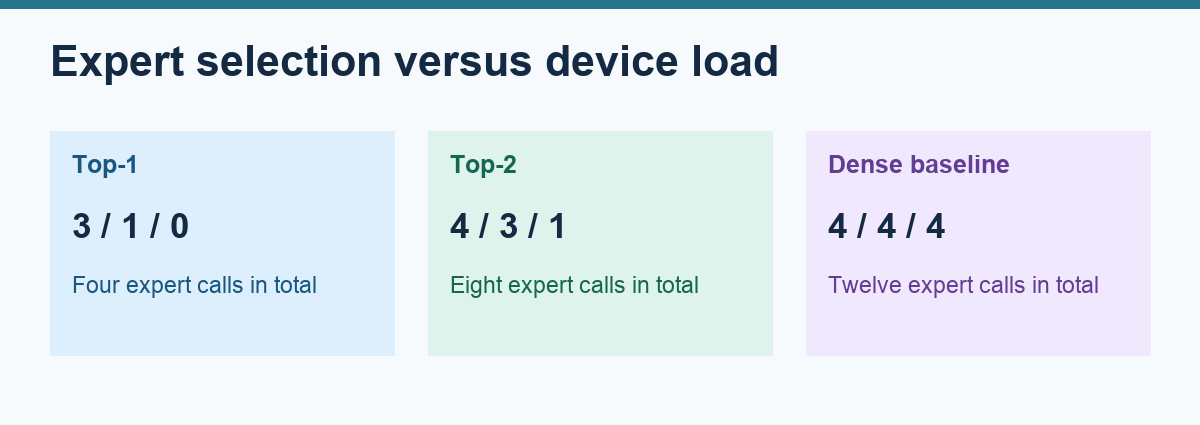

## Optional extension · Per-token sparsity and batch coverage

Kiely distinguishes the experts selected for an individual token from the union of experts activated by a batch. Routing happens again at each mixture-of-experts layer. Our notebook models one layer. Even when each token uses only one expert, a batch with varied router scores can use every expert in the layer.

Compare a batch where every token routes to expert 0 with a batch in which different tokens prefer different experts. Keep top-k fixed at one and compare total assignments, distinct active experts, and the busiest expert.

**Reading** · Philip Kiely, *Inference Engineering*, §2.2.4, pp. 53–54.

In [ ]:
from collections import Counter

batches = [[[3, 1, 0]] * 3, [[3, 1, 0], [0, 3, 1], [0, 1, 3]]]
for batch in batches:
    counts = Counter(max(range(len(row)), key=row.__getitem__) for row in batch)
    assert sum(counts.values()) == 3
    print("Assignments:", sum(counts.values()), "active:", len(counts),
          "busiest:", max(counts.values()))

## Wrap-up

Change the router scores so top-1 requests are spread across experts. Compare the busiest expert and the total number of calls. If each expert were on a separate device, which count would help you reason about the longest queue?

## Optional system exercise · Per-device load instead of average load

Assume each expert is on a separate device and each call takes one unit of time. Use the per-expert counts to estimate the longest device queue under top-1 and top-2. State what this model leaves out, such as dispatch and expert batching.